# Regresja profil eCHORD → orientacja: testy na danych symulowanych

Prawdziwe orientacje są losowane, profile liczone dokładnie (`cone_profiles`), potem ewentualnie
psute (gain/offset, tło, szum) i odwracane przez `orient_fit`. Porównujemy trzy źródła błędu:

| eksperyment | dane → model | co mierzy |
|---|---|---|
| A | cone → cone, bez szumu | błąd samego algorytmu (powinien być ≈ 0) |
| B | cone → cone, szum | odporność na szum, identyfikowalność |
| C | cone → cone, tło | czy usuwanie niskich harmonik nie niszczy informacji (polarność!) |
| D | cone → GP | błąd emulatora |

Diagnostyka dla każdego profilu: `r_true` = korelacja modelu w **prawdziwej** orientacji.
Przy dużym błędzie: `r_est < r_true` → porażka **szukania**; `r_est ≥ r_true` → **model /
identyfikowalność** (model naprawdę woli złą orientację). `mis_d4` = dezorientacja modulo 4/mmm,
czyli ignorująca polarność (+c/−c).

## 0. Parametry

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation

import echord_cone as ec
import orient_fit as of

MASTER  = "../2026_10_19_example_PZ/masterKTN_014_01.h5"
# GP_PATH = "gp_ktn_th40.npz"      # .npz = numpy, inne rozszerzenie = GPyTorch; None -> bez D
GP_PATH  = "model.pt"
NEAR_ANGLES = None               # plik kątów EMsoftu (np. wyniki metody słownikowej) albo None
NEAR_SPREAD = 2.0                # [deg] rozrzut orientacji testowych wokół NEAR_ANGLES

THETA, INVERT, SIGMA_CONV, DPSI = 40.0, False, 0.0, 0.25   # nadpisywane z meta GP, jeśli jest
PHI0, SENSE = 13.0, -1           # celowo "nieładne", żeby sprawdzić księgowanie przesunięć
N_TEST  = 100
SPACING = 0.7                    # [deg] oczko banku (Phi, phi2)
TOP_K   = 5
USE_VARIANTS = True              # sprawdzaj jawnie 6 wariantów pseudoregularnych (O / C4)
N_REFINE = 6                     # ile najlepszych startów (po ocenie w punkcie) optymalizować;
                                 # None = wszystkie TOP_K*6 (wolno, zwłaszcza z GP)
SEED    = 0
BANK_CACHE = "bank"              # prefiks plików z bankiem; None = bez zapisu

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Master, symetria, modele

In [2]:
mp = ec.MasterPattern(MASTER)
print(mp)
sym = of.mirror_symmetry_check(mp)
print("\nkorelacja M(d) z M(Sd):", {k: round(v, 4) for k, v in sym.items()})
if min(sym["mirror_x"], sym["mirror_diag"]) > 0.999:
    print("-> lustra 4mm obecne: sense i invert NIE są wyznaczalne z profili (ustala je konwencja)")
print(f"-> łamanie prawa Friedla: względna różnica rms M(d) - M(-d) ≈ "
      f"{np.sqrt(2 * (1 - sym['inversion'])):.2f} odchylenia standardowego")

MasterPattern('../2026_10_19_example_PZ/masterKTN_014_01.h5')
  dataset : EMData/ECPmaster/mLPNH, surowy kształt (4, 1025, 1025)
  npx     : 512  (obraz 1025^2)
  energie : brak, wybór: max
  accum_e : nie, masterSPNH: tak
  kryształ: grupa przestrzenna 99, centrosymetryczna: False, parametry sieci: [ 0.39930001  0.39930001  0.40019998 90.         90.         90.        ]

korelacja M(d) z M(Sd): {'mirror_x': 1.0, 'mirror_diag': 1.0, 'inversion': 0.9531}
-> lustra 4mm obecne: sense i invert NIE są wyznaczalne z profili (ustala je konwencja)
-> łamanie prawa Friedla: względna różnica rms M(d) - M(-d) ≈ 0.31 odchylenia standardowego


In [3]:
gpm = None
if GP_PATH and os.path.exists(GP_PATH):
    import gp_echord as G
    if GP_PATH.endswith(".npz"):            # wersja numpy (gp_echord)
        gp_raw = G.EchordGP.load(GP_PATH)
    else:                                   # wersja GPyTorch (torch.save); load liczy Cholesky'ego
        import gp_echord_gpytorch as GT
        gp_raw = GT.TorchEchordGP.load(GP_PATH)
    gpm = of.GPModel(gp_raw)
    THETA, INVERT = gpm.coneAngle, gpm.invert
    SIGMA_CONV, DPSI = gpm.sigma_conv_deg, gpm.dpsi
    r, err = of.self_check(gpm)
    print(f"self_check GP: min r = {r:.8f}, max błąd/std = {err:.2e}")
    assert r > 0.9999, "bank kanoniczny GP != predict_profiles: popraw GPModel.canonical_X"
else:
    print("brak emulatora -> eksperyment D zostanie pominięty")

cone = of.ConeModel(mp, THETA, INVERT, SIGMA_CONV, DPSI)
print("self_check cone:", of.self_check(cone))
print(f"theta = {THETA}°, invert = {INVERT}, sigma_conv = {SIGMA_CONV}°, dpsi = {DPSI}°")

[warunkowanie/GPyTorch] Cholesky 32384x32384, 126.9 s
self_check GP: min r = 0.99999996, max błąd/std = 4.64e-07
self_check cone: (0.999999956731345, 4.126728805649793e-07)
theta = 40.0°, invert = False, sigma_conv = 0.0°, dpsi = 0.25°


## 2. Bank startów

Bank profili kanonicznych z `cone_profiles` (szybko i dokładnie) — służy tylko do wyboru
basenu, więc używamy go także dla GP. Wariancje F na grzebieniu liczą się przy pierwszym
profilu danej geometrii (pierwszy profil jest wolniejszy).

In [4]:
def get_bank(model, spacing=SPACING, n_bg_harm=0):
    path = f"{BANK_CACHE}_{model.name}_sp{spacing}_bg{n_bg_harm}.npz" if BANK_CACHE else None
    if path and os.path.exists(path):
        print(f"[bank] wczytany {path}")
        return of.Bank.load(path)
    b = of.build_bank(model, spacing, n_bg_harm=n_bg_harm)
    if path:
        b.save(path)
    return b

bank = get_bank(cone)

[bank] wczytany bank_cone_sp0.7_bg0.npz


## 2b. Jak podobne są warianty pseudoregularne?

Dla losowych g: korelacja profilu g z profilem V·g (dokładny model cone) dla 5 nietrywialnych
wariantów V. To wyznacza wymaganą dokładność emulatora: jeśli 1 − r(g, Vg) jest porównywalne
z błędem emulatora 1 − r_true, GP nie odróżni wariantów.

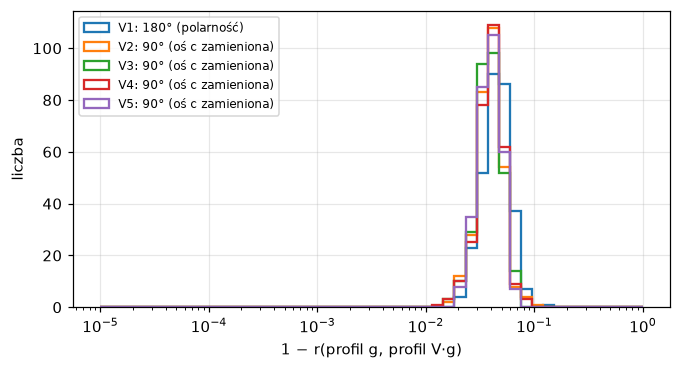

mediany 1 - r: [0.0455 0.0396 0.0389 0.0397 0.0396]
najbliższy wariant, mediana 1 - r: 0.0324


In [5]:
Vs = of.pseudo_variants()
g_s = of.random_orientations(300, seed=123)
P = cone.profiles(g_s, PHI0, SENSE)
sim = np.stack([of.pearson(P, cone.profiles(V @ g_s, PHI0, SENSE)) for V in Vs[1:]], 1)
def _vname(k, V):
    m = of.misorientation_deg(V, np.eye(3))[0]
    m4 = of.misorientation_deg(V, np.eye(3), of.d4_ops())[0]
    return f"V{k}: {m:.0f}°" + (" (polarność)" if m4 < 1 else " (oś c zamieniona)")
names = [_vname(k, V) for k, V in enumerate(Vs[1:], 1)]
fig, ax = plt.subplots(figsize=(7, 3.5))
for k in range(sim.shape[1]):
    ax.hist(np.clip(1 - sim[:, k], 1e-5, None), bins=np.logspace(-5, 0, 50), histtype="step",
            lw=1.5, label=names[k])
ax.set_xscale("log"); ax.set_xlabel("1 − r(profil g, profil V·g)"); ax.set_ylabel("liczba")
ax.legend(fontsize=8); plt.show()
print("mediany 1 - r:", np.round(np.median(1 - sim, 0), 4))
print("najbliższy wariant, mediana 1 - r:", np.round(np.median(1 - sim.max(1)), 4))

## 3. Funkcje pomocnicze: dane testowe, pętla dopasowań, podsumowanie

In [6]:
D4 = of.d4_ops()
O24 = of.cubic_ops()
VARIANTS = of.pseudo_variants() if USE_VARIANTS else None

def make_truth(n, seed=SEED):
    if NEAR_ANGLES is None:
        return of.random_orientations(n, seed)
    rep, data = ec.read_anglefile(NEAR_ANGLES)
    G0 = ec.to_matrices(data, rep=rep)
    rng = np.random.default_rng(seed)
    base = G0[rng.integers(len(G0), size=n)]
    v = rng.normal(size=(n, 3))
    v *= np.deg2rad(NEAR_SPREAD) * rng.random((n, 1)) / np.linalg.norm(v, axis=1, keepdims=True)
    return base @ Rotation.from_rotvec(v).as_matrix()


def perturb(Y, snr=np.inf, gain_sd=0.0, bg_amp=0.0, seed=1):
    # gain*Y + offset + tło (harmoniki 1..3, amplituda bg_amp*std) + szum (std/snr)
    rng = np.random.default_rng(seed)
    s = Y.std(axis=1, keepdims=True)
    out = (1 + gain_sd * rng.normal(size=(len(Y), 1))) * Y + s * rng.normal(size=(len(Y), 1))
    if bg_amp > 0:
        w = np.deg2rad(cone.omega)[None, :]
        for k in (1, 2, 3):
            out += bg_amp * s / k * np.cos(k * w + rng.uniform(0, 2 * np.pi, (len(Y), 1)))
    if np.isfinite(snr):
        out += rng.normal(size=Y.shape) * s / snr
    return out


def run_fits(model, bank, Y, g_true, n_bg_harm=0, label=""):
    rows, t0 = [], time.perf_counter()
    every = max(1, len(Y) // 10)
    e_true = of.euler_from_matrix(g_true)
    for i, y in enumerate(Y):
        if i and i % every == 0:
            el = time.perf_counter() - t0
            print(f"  [{label}] {i}/{len(Y)}  {el:.0f} s, zostało ~{el / i * (len(Y) - i):.0f} s",
                  flush=True)
        res = of.fit_profile(model, bank, y, PHI0, SENSE, top_k=TOP_K, n_bg_harm=n_bg_harm,
                             variants=VARIANTS, n_refine=N_REFINE)
        e = of.euler_from_matrix(res["g"])[0]
        rows.append(dict(
            mis=of.misorientation_deg(res["g"], g_true[i])[0],
            mis_d4=of.misorientation_deg(res["g"], g_true[i], D4)[0],
            mis_o=of.misorientation_deg(res["g"], g_true[i], O24)[0],
            r_est=res["r"],
            r_true=of.cost_r(model, y, g_true[i], PHI0, SENSE, n_bg_harm=n_bg_harm)[0],
            r_seed=res["r_seed"], seed_rank=res["seed_rank"], step_deg=res["step_deg"],
            phi1_true=e_true[i, 0], Phi_true=e_true[i, 1], phi2_true=e_true[i, 2],
            phi1_est=e[0], Phi_est=e[1], phi2_est=e[2], g_est=res["g"]))
    df = pd.DataFrame(rows)
    big = df.mis > 2
    df["klasa"] = np.where(~big, "ok",
                  np.where(df.r_est < df.r_true - 1e-6, "szukanie",
                  np.where(df.mis_d4 < 2, "polarność",
                  np.where(df.mis_o < 2, "wariant 90°", "model"))))
    print(f"  [{label}] gotowe: {(time.perf_counter() - t0) / len(Y):.2f} s/profil")
    return df


def summary(dfs: dict):
    out = {}
    for name, df in dfs.items():
        out[name] = {
            "mediana [°]": df.mis.median(), "p90 [°]": df.mis.quantile(0.9),
            ">1°": (df.mis > 1).mean(), ">2°": (df.mis > 2).mean(),
            "szukanie": (df.klasa == "szukanie").sum(), "polarność": (df.klasa == "polarność").sum(),
            "wariant 90°": (df.klasa == "wariant 90°").sum(),
            "model": (df.klasa == "model").sum(),
            "med r_est": df.r_est.median(), "med r_true": df.r_true.median(),
            "start z rangą>0": (df.seed_rank > 0).mean()}
    return (pd.DataFrame(out).T.style
            .format({"mediana [°]": "{:.3f}", "p90 [°]": "{:.3f}", ">1°": "{:.1%}", ">2°": "{:.1%}",
                     "szukanie": "{:.0f}", "polarność": "{:.0f}", "wariant 90°": "{:.0f}", "model": "{:.0f}",
                     "med r_est": "{:.4f}", "med r_true": "{:.4f}", "start z rangą>0": "{:.0%}"}))


def plot_mis_hist(dfs: dict, title=""):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    bins = np.logspace(-4, np.log10(181), 60)
    for name, df in dfs.items():
        ax.hist(np.clip(df.mis, 1e-4, None), bins=bins, histtype="step", lw=1.5, label=name)
    ax.set_xscale("log"); ax.set_xlabel("dezorientacja mod C4 [°]"); ax.set_ylabel("liczba")
    ax.set_title(title); ax.legend()
    plt.show()

def run(name, model, bank, Y, n_bg_harm=0):
    # dopasowuje wszystkie profile Y, zapamiętuje wynik i dane wejściowe (do sekcji F)
    results[name] = run_fits(model, bank, Y, g_true, n_bg_harm, label=name)
    EXP[name] = dict(Y=Y, model=model, bank=bank, nbh=n_bg_harm)
    return results[name]

g_true = make_truth(N_TEST)
Y0 = cone.profiles(g_true, PHI0, SENSE)       # profile bez zaburzeń
results = {}                                  # nazwa eksperymentu -> DataFrame z wynikami
EXP = {}                                      # nazwa eksperymentu -> dane wejściowe i ustawienia
print(Y0.shape)

(100, 180)


## A. Algorytm: cone → cone, bez szumu (tylko gain/offset)

Oczekiwane: dezorientacja ≈ 0 i `r_est` ≈ 1 dla wszystkich. Cokolwiek innego to błąd
w kodzie albo w księgowaniu φ0/sense, a nie fizyka.

In [7]:
run("A: cone, bez szumu", cone, bank, perturb(Y0, gain_sd=0.3))
summary({k: v for k, v in results.items() if k.startswith("A")})

  [A: cone, bez szumu] 10/100  3 s, zostało ~25 s
  [A: cone, bez szumu] 20/100  5 s, zostało ~22 s
  [A: cone, bez szumu] 30/100  8 s, zostało ~19 s
  [A: cone, bez szumu] 40/100  11 s, zostało ~16 s
  [A: cone, bez szumu] 50/100  13 s, zostało ~13 s
  [A: cone, bez szumu] 60/100  16 s, zostało ~11 s
  [A: cone, bez szumu] 70/100  18 s, zostało ~8 s
  [A: cone, bez szumu] 80/100  21 s, zostało ~5 s
  [A: cone, bez szumu] 90/100  24 s, zostało ~3 s
  [A: cone, bez szumu] gotowe: 0.26 s/profil


,mediana [°],p90 [°],>1°,>2°,szukanie,polarność,wariant 90°,model,med r_est,med r_true,start z rangą>0
"A: cone, bez szumu",0.000,0.000,0.0%,0.0%,0,0,0,0,1.0000,1.0000,40%


## B. Szum: skan SNR

SNR = std(profilu) / std(szumu). Do porównania z pomiarem: oszacuj SNR swoich pikseli
(np. różnica dwóch pikseli o niemal identycznych profilach, jak (15,15) i (46,20)).

  [B: cone, SNR 20] 10/100  3 s, zostało ~23 s
  [B: cone, SNR 20] 20/100  5 s, zostało ~21 s
  [B: cone, SNR 20] 30/100  8 s, zostało ~18 s
  [B: cone, SNR 20] 40/100  11 s, zostało ~16 s
  [B: cone, SNR 20] 50/100  13 s, zostało ~13 s
  [B: cone, SNR 20] 60/100  16 s, zostało ~10 s
  [B: cone, SNR 20] 70/100  18 s, zostało ~8 s
  [B: cone, SNR 20] 80/100  21 s, zostało ~5 s
  [B: cone, SNR 20] 90/100  23 s, zostało ~3 s
  [B: cone, SNR 20] gotowe: 0.26 s/profil
  [B: cone, SNR 10] 10/100  3 s, zostało ~24 s
  [B: cone, SNR 10] 20/100  5 s, zostało ~21 s
  [B: cone, SNR 10] 30/100  8 s, zostało ~18 s
  [B: cone, SNR 10] 40/100  10 s, zostało ~16 s
  [B: cone, SNR 10] 50/100  13 s, zostało ~13 s
  [B: cone, SNR 10] 60/100  16 s, zostało ~10 s
  [B: cone, SNR 10] 70/100  18 s, zostało ~8 s
  [B: cone, SNR 10] 80/100  21 s, zostało ~5 s
  [B: cone, SNR 10] 90/100  23 s, zostało ~3 s
  [B: cone, SNR 10] gotowe: 0.26 s/profil
  [B: cone, SNR 5] 10/100  3 s, zostało ~24 s
  [B: cone, SNR 5]

,mediana [°],p90 [°],>1°,>2°,szukanie,polarność,wariant 90°,model,med r_est,med r_true,start z rangą>0
"A: cone, bez szumu",0.000,0.000,0.0%,0.0%,0,0,0,0,1.0000,1.0000,40%
"B: cone, SNR 20",0.005,0.012,0.0%,0.0%,0,0,0,0,0.9988,0.9988,60%
"B: cone, SNR 10",0.009,0.019,0.0%,0.0%,0,0,0,0,0.9944,0.9944,45%
"B: cone, SNR 5",0.018,0.038,0.0%,0.0%,0,0,0,0,0.9780,0.9774,60%
"B: cone, SNR 3",0.029,0.060,3.0%,3.0%,0,0,2,1,0.9499,0.9483,54%


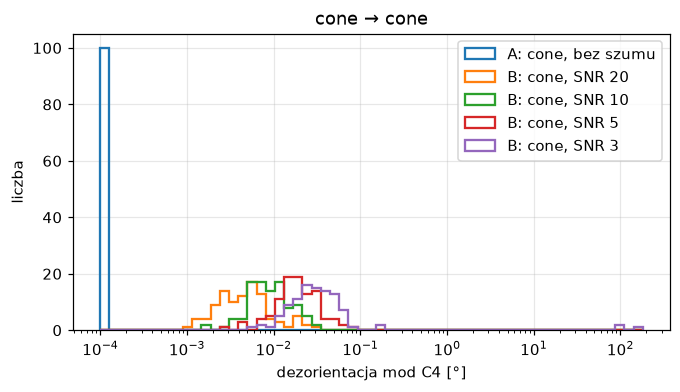

In [8]:
SNRS = [20, 10, 5, 3]
for snr in SNRS:
    run(f"B: cone, SNR {snr}", cone, bank, perturb(Y0, snr, 0.3, seed=snr))
B = {k: v for k, v in results.items() if k.startswith(("A", "B"))}
display(summary(B))
plot_mis_hist(B, "cone → cone")

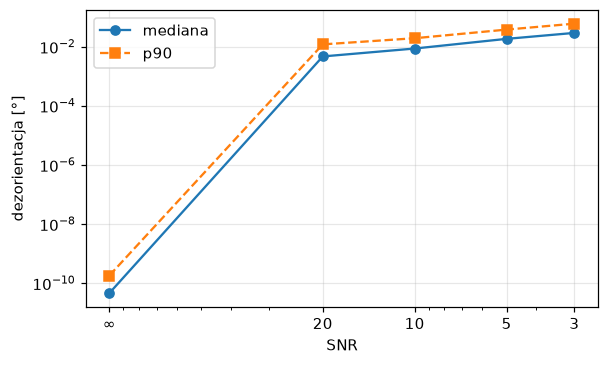

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
snr_axis = [np.inf] + SNRS
dfs = [results["A: cone, bez szumu"]] + [results[f"B: cone, SNR {s}"] for s in SNRS]
x = [100] + SNRS                               # "inf" narysowane jako 100
ax.plot(x, [d.mis.median() for d in dfs], "o-", label="mediana")
ax.plot(x, [d.mis.quantile(0.9) for d in dfs], "s--", label="p90")
ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_xaxis()
ax.set_xticks(x); ax.set_xticklabels(["∞"] + [str(s) for s in SNRS])
ax.set_xlabel("SNR"); ax.set_ylabel("dezorientacja [°]"); ax.legend()
plt.show()

## C. Tło niskich częstości i jego usuwanie

Tło w harmonikach 1–3 (amplituda równa std profilu, jak u Ciebie ~3–5× to raczej więcej).
Porównujemy dopasowanie bez usuwania tła (`n_bg_harm = 0`) i z usunięciem harmonik 0–3.
Patrz kolumna **polarność**: jeśli informacja o +c/−c siedzi w niskich harmonikach,
usuwanie tła ją zabija.

In [10]:
SNR_C, BG_AMP, NBH = 10, 1.0, 3
Yc = perturb(Y0, SNR_C, 0.3, bg_amp=BG_AMP, seed=77)
bank_bg = get_bank(cone, n_bg_harm=NBH)
run("C: tło, bez usuwania", cone, bank, Yc, 0)
run(f"C: tło, usunięte 0..{NBH}", cone, bank_bg, Yc, NBH)
# kontrola: to samo usuwanie harmonik, ale dane BEZ tła -> czysty koszt utraty informacji
run(f"C: bez tła, usunięte 0..{NBH}", cone, bank_bg, perturb(Y0, SNR_C, 0.3, seed=77), NBH)
summary({k: v for k, v in results.items() if k.startswith("C") or k == f"B: cone, SNR {SNR_C}"})

[bank] wczytany bank_cone_sp0.7_bg3.npz
  [C: tło, bez usuwania] 10/100  3 s, zostało ~23 s
  [C: tło, bez usuwania] 20/100  5 s, zostało ~21 s
  [C: tło, bez usuwania] 30/100  8 s, zostało ~18 s
  [C: tło, bez usuwania] 40/100  10 s, zostało ~16 s
  [C: tło, bez usuwania] 50/100  13 s, zostało ~13 s
  [C: tło, bez usuwania] 60/100  16 s, zostało ~11 s
  [C: tło, bez usuwania] 70/100  18 s, zostało ~8 s
  [C: tło, bez usuwania] 80/100  21 s, zostało ~5 s
  [C: tło, bez usuwania] 90/100  24 s, zostało ~3 s
  [C: tło, bez usuwania] gotowe: 0.26 s/profil
  [C: tło, usunięte 0..3] 10/100  3 s, zostało ~26 s
  [C: tło, usunięte 0..3] 20/100  6 s, zostało ~22 s
  [C: tło, usunięte 0..3] 30/100  8 s, zostało ~19 s
  [C: tło, usunięte 0..3] 40/100  11 s, zostało ~16 s
  [C: tło, usunięte 0..3] 50/100  14 s, zostało ~14 s
  [C: tło, usunięte 0..3] 60/100  16 s, zostało ~11 s
  [C: tło, usunięte 0..3] 70/100  19 s, zostało ~8 s
  [C: tło, usunięte 0..3] 80/100  21 s, zostało ~5 s
  [C: tło, usun

,mediana [°],p90 [°],>1°,>2°,szukanie,polarność,wariant 90°,model,med r_est,med r_true,start z rangą>0
"B: cone, SNR 10",0.009,0.019,0.0%,0.0%,0,0,0,0,0.9944,0.9944,45%
"C: tło, bez usuwania",0.074,90.096,23.0%,23.0%,0,3,17,3,0.7790,0.7742,52%
"C: tło, usunięte 0..3",0.009,0.017,0.0%,0.0%,0,0,0,0,0.9950,0.9950,53%
"C: bez tła, usunięte 0..3",0.009,0.019,0.0%,0.0%,0,0,0,0,0.9949,0.9948,59%


## D. Emulator: cone → GP

Bank startów ten sam (z cone). Różnica względem A/B to błąd emulatora. Dodatkowo:
czy duży błąd idzie w parze z dużą σ_GP (czyli czy GP „wie”, że się myli).

In [11]:
if gpm is not None:
    run("D: GP, bez szumu", gpm, bank, perturb(Y0, gain_sd=0.3))
    run("D: GP, SNR 10", gpm, bank, perturb(Y0, 10, 0.3, seed=10))
    _, sd_true = gpm.profiles_std(g_true, PHI0, SENSE)
    for k in ("D: GP, bez szumu", "D: GP, SNR 10"):
        results[k]["sd_true"] = sd_true
    display(summary({k: results[k] for k in
                     ["A: cone, bez szumu", "D: GP, bez szumu", "B: cone, SNR 10", "D: GP, SNR 10"]}))
else:
    print("pominięte (brak emulatora)")

  [D: GP, bez szumu] 10/100  33 s, zostało ~301 s
  [D: GP, bez szumu] 20/100  64 s, zostało ~258 s
  [D: GP, bez szumu] 30/100  94 s, zostało ~219 s
  [D: GP, bez szumu] 40/100  124 s, zostało ~186 s
  [D: GP, bez szumu] 50/100  153 s, zostało ~153 s
  [D: GP, bez szumu] 60/100  185 s, zostało ~123 s
  [D: GP, bez szumu] 70/100  214 s, zostało ~92 s
  [D: GP, bez szumu] 80/100  244 s, zostało ~61 s
  [D: GP, bez szumu] 90/100  275 s, zostało ~31 s
  [D: GP, bez szumu] gotowe: 3.09 s/profil
  [D: GP, SNR 10] 10/100  37 s, zostało ~330 s
  [D: GP, SNR 10] 20/100  68 s, zostało ~272 s
  [D: GP, SNR 10] 30/100  100 s, zostało ~233 s
  [D: GP, SNR 10] 40/100  130 s, zostało ~195 s
  [D: GP, SNR 10] 50/100  158 s, zostało ~158 s
  [D: GP, SNR 10] 60/100  189 s, zostało ~126 s
  [D: GP, SNR 10] 70/100  218 s, zostało ~93 s
  [D: GP, SNR 10] 80/100  247 s, zostało ~62 s
  [D: GP, SNR 10] 90/100  279 s, zostało ~31 s
  [D: GP, SNR 10] gotowe: 3.19 s/profil


,mediana [°],p90 [°],>1°,>2°,szukanie,polarność,wariant 90°,model,med r_est,med r_true,start z rangą>0
"A: cone, bez szumu",0.000,0.000,0.0%,0.0%,0,0,0,0,1.0000,1.0000,40%
"D: GP, bez szumu",0.066,90.054,28.0%,28.0%,1,0,27,0,0.9721,0.9683,70%
"B: cone, SNR 10",0.009,0.019,0.0%,0.0%,0,0,0,0,0.9944,0.9944,45%
"D: GP, SNR 10",0.071,90.051,28.0%,28.0%,0,0,28,0,0.9659,0.9617,67%


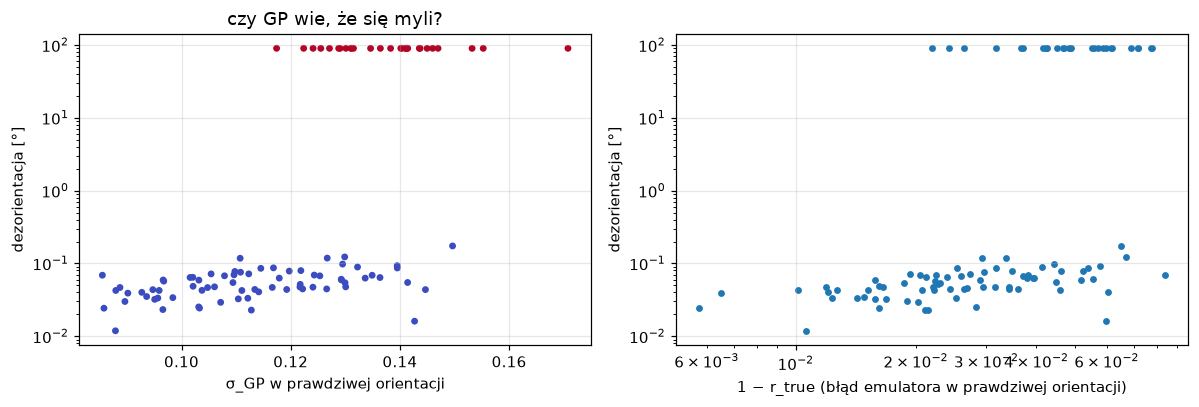

In [12]:
if gpm is not None:
    df = results["D: GP, bez szumu"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].scatter(df.sd_true, np.clip(df.mis, 1e-4, None), s=12, c=df.klasa.eq("ok"), cmap="coolwarm_r")
    ax[0].set_yscale("log"); ax[0].set_xlabel("σ_GP w prawdziwej orientacji")
    ax[0].set_ylabel("dezorientacja [°]"); ax[0].set_title("czy GP wie, że się myli?")
    ax[1].scatter(1 - df.r_true, np.clip(df.mis, 1e-4, None), s=12)
    ax[1].set_xscale("log"); ax[1].set_yscale("log")
    ax[1].set_xlabel("1 − r_true (błąd emulatora w prawdziwej orientacji)")
    ax[1].set_ylabel("dezorientacja [°]")
    plt.tight_layout(); plt.show()

## E. Gdzie są błędy? Zależność od orientacji

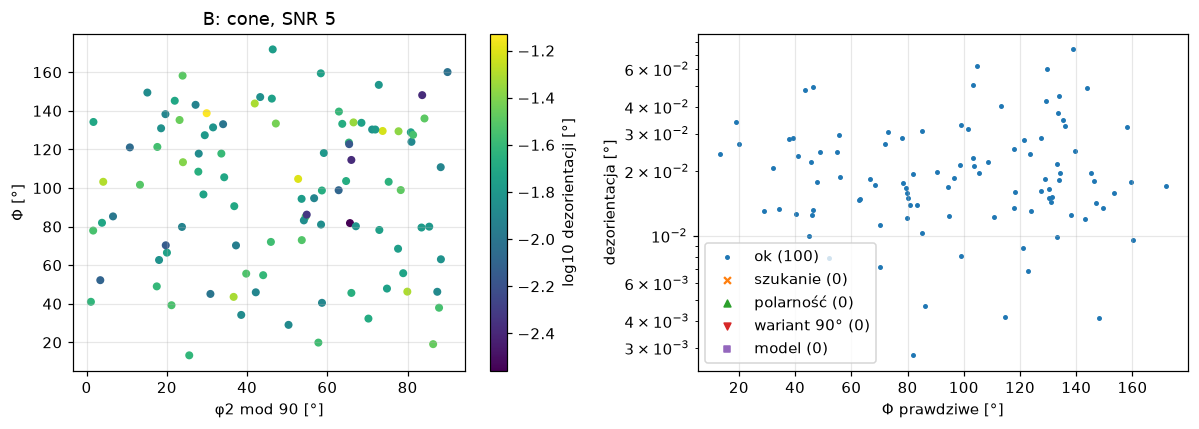

In [13]:
NAME = "B: cone, SNR 5"          # dowolny klucz z results
df = results[NAME]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(df.phi2_true % 90, df.Phi_true, c=np.log10(np.clip(df.mis, 1e-3, None)),
                   s=18, cmap="viridis")
plt.colorbar(sc, ax=ax[0], label="log10 dezorientacji [°]")
ax[0].set_xlabel("φ2 mod 90 [°]"); ax[0].set_ylabel("Φ [°]"); ax[0].set_title(NAME)
for kl, m in [("ok", "."), ("szukanie", "x"), ("polarność", "^"), ("wariant 90°", "v"),
              ("model", "s")]:
    d = df[df.klasa == kl]
    ax[1].scatter(d.Phi_true, np.clip(d.mis, 1e-4, None), marker=m, s=20, label=f"{kl} ({len(d)})")
ax[1].set_yscale("log"); ax[1].set_xlabel("Φ prawdziwe [°]"); ax[1].set_ylabel("dezorientacja [°]")
ax[1].legend()
plt.tight_layout(); plt.show()

## F. Najgorsze przypadki: profile i krajobraz korelacji

Dla wybranego przypadku: pomiar vs model w orientacji znalezionej i prawdziwej (po normalizacji)
oraz mapa max_φ1 r w płaszczyźnie (φ2, Φ) z banku — widać, czy są konkurencyjne baseny
(np. Φ ↔ 180° − Φ przy pomyłce polarności).

mis            0.074132
mis_d4         0.074132
r_est          0.912907
r_true         0.911922
klasa                ok
Phi_true     138.758113
Phi_est       138.76849
phi2_true       209.927
phi2_est     119.878694


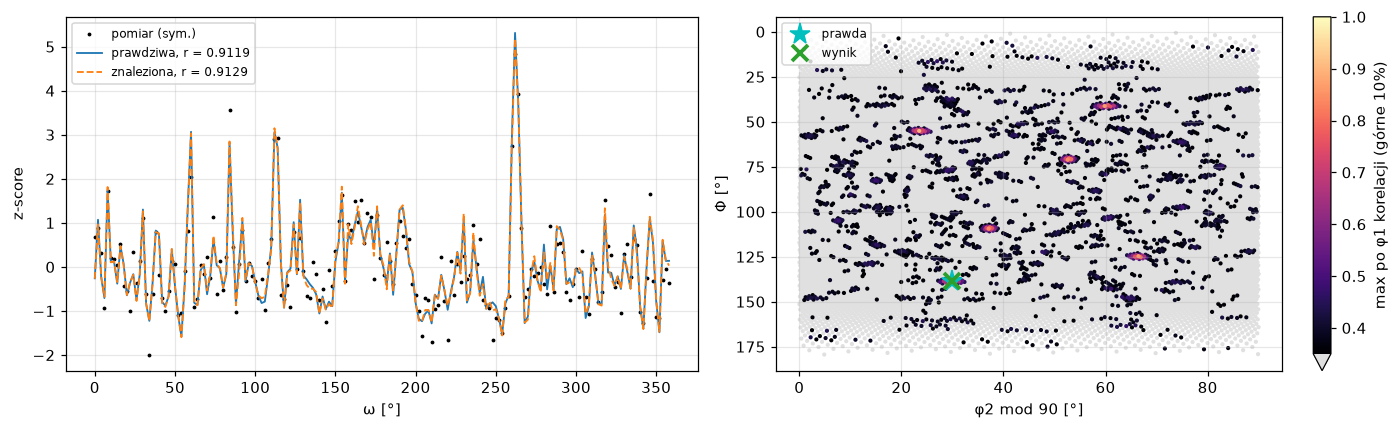

In [14]:
NAME = "B: cone, SNR 5"
WHICH = 0                        # 0 = najgorszy, 1 = drugi najgorszy, ...
df = results[NAME]
i = df.mis.sort_values(ascending=False).index[WHICH]
ex = EXP[NAME]
model, nbh, b, y = ex["model"], ex["nbh"], ex["bank"], ex["Y"][i]

def z(v):
    v = of.highpass(v, nbh) if nbh else v
    return (v - v.mean()) / v.std()

mu_est = model.profiles(df.g_est[i][None], PHI0, SENSE)[0]
mu_true = model.profiles(g_true[i][None], PHI0, SENSE)[0]
print(df.loc[i, ["mis", "mis_d4", "r_est", "r_true", "klasa", "Phi_true", "Phi_est",
                 "phi2_true", "phi2_est"]].to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(cone.omega, z(y), "k.", ms=3, label="pomiar (sym.)")
ax[0].plot(cone.omega, z(mu_true), lw=1.2, label=f"prawdziwa, r = {df.r_true[i]:.4f}")
ax[0].plot(cone.omega, z(mu_est), lw=1.2, ls="--", label=f"znaleziona, r = {df.r_est[i]:.4f}")
ax[0].set_xlabel("ω [°]"); ax[0].set_ylabel("z-score"); ax[0].legend(fontsize=8)

yy = of.highpass(y, nbh) if nbh else y
rmax = np.concatenate([of.shift_correlation(b, yy, cone.omega, PHI0, SENSE,
                                            rows=slice(s, s + 4096)).max(1)
                       for s in range(0, len(b.angles), 4096)])
o = np.argsort(rmax)                       # najwyższe r rysowane na wierzchu
cmap = plt.get_cmap("magma").copy(); cmap.set_under("0.88")
sc = ax[1].scatter(b.angles[o, 1], b.angles[o, 0], c=rmax[o], s=3, cmap=cmap,
                   vmin=np.quantile(rmax, 0.9), vmax=1)
plt.colorbar(sc, ax=ax[1], label="max po φ1 korelacji (górne 10%)", extend="min")
ax[1].plot(df.phi2_true[i] % 90, df.Phi_true[i], "c*", ms=14, label="prawda")
ax[1].plot(df.phi2_est[i] % 90, df.Phi_est[i], "x", color="tab:green", ms=11, mew=2.5,
           label="wynik")
ax[1].set_xlabel("φ2 mod 90 [°]"); ax[1].set_ylabel("Φ [°]"); ax[1].invert_yaxis()
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## G. Zestawienie i zapis

In [15]:
display(summary(results))
pd.concat({k: v.drop(columns="g_est") for k, v in results.items()}, names=["eksperyment", "i"]) \
  .to_csv("inversion_tests.csv")
np.savez_compressed("inversion_tests_truth.npz", g_true=g_true, Y0=Y0,
                    euler_true=of.euler_from_matrix(g_true))
print("zapisano inversion_tests.csv, inversion_tests_truth.npz")

,mediana [°],p90 [°],>1°,>2°,szukanie,polarność,wariant 90°,model,med r_est,med r_true,start z rangą>0
"A: cone, bez szumu",0.000,0.000,0.0%,0.0%,0,0,0,0,1.0000,1.0000,40%
"B: cone, SNR 20",0.005,0.012,0.0%,0.0%,0,0,0,0,0.9988,0.9988,60%
"B: cone, SNR 10",0.009,0.019,0.0%,0.0%,0,0,0,0,0.9944,0.9944,45%
"B: cone, SNR 5",0.018,0.038,0.0%,0.0%,0,0,0,0,0.9780,0.9774,60%
"B: cone, SNR 3",0.029,0.060,3.0%,3.0%,0,0,2,1,0.9499,0.9483,54%
"C: tło, bez usuwania",0.074,90.096,23.0%,23.0%,0,3,17,3,0.7790,0.7742,52%
"C: tło, usunięte 0..3",0.009,0.017,0.0%,0.0%,0,0,0,0,0.9950,0.9950,53%
"C: bez tła, usunięte 0..3",0.009,0.019,0.0%,0.0%,0,0,0,0,0.9949,0.9948,59%
"D: GP, bez szumu",0.066,90.054,28.0%,28.0%,1,0,27,0,0.9721,0.9683,70%
"D: GP, SNR 10",0.071,90.051,28.0%,28.0%,0,0,28,0,0.9659,0.9617,67%


zapisano inversion_tests.csv, inversion_tests_truth.npz
